# Módulo 5: Regressão Linear Múltipla e Padronização de Dados

> **Resumo Didático Integrado** — Baseado no *Capítulo 3 (Análise de Dados — Seção 2: Regressão Múltipla & Padronização)*.

## 1. Visão Geral e Fundamentação Matemática

### 1.1 A Equação da Regressão Linear Múltipla
Na maioria dos cenários reais, um único fator é insuficiente para explicar a variabilidade de um fenômeno. A regressão linear múltipla expande a equação linear para $k$ variáveis preditoras:

$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_k X_k + \epsilon$$

Onde cada coeficiente parcial $\beta_j$ representa o impacto de $X_j$ sobre $Y$, **mantendo todas as demais variáveis constantes** (*ceteris paribus*).


### 1.2 O Coeficiente de Determinação Ajustado ($R^2_{adj}$)
Diferente da regressão simples, na regressão múltipla o $R^2$ comum **nunca diminui** quando adicionamos novas variáveis — mesmo que sejam variáveis aleatórias irrelevantes. Por isso, utilizamos o **$R^2$ Ajustado**:

$$R^2_{adj} = 1 - \left[ \frac{(1 - R^2)(n - 1)}{n - k - 1} \right]$$

Onde $n$ é o número de observações e $k$ é a quantidade de preditores. O $R^2_{adj}$ penaliza a inclusão de variáveis desnecessárias e só aumenta se o novo preditor realmente melhorar o poder explicativo do modelo além do mero acaso.


### 1.3 Diagnóstico de Multicolinearidade (VIF)
A **Multicolinearidade** ocorre quando duas ou mais variáveis preditoras são fortemente correlacionadas entre si. Isso infla a variância das estimativas dos coeficientes, tornando-os instáveis. O indicador padrão de diagnóstico é o **Fator de Inflação da Variância (VIF - *Variance Inflation Factor*)**:

$$VIF_j = \frac{1}{1 - R_j^2}$$

* $VIF \approx 1$: Ausência de colinearidade.
* $VIF > 5$: Alerta moderado de multicolinearidade.
* $VIF > 10$: Multicolinearidade severa (recomenda-se remover ou combinar os preditores colineares).


### 1.4 Termos de Interação (*Interaction Terms*) e Efeito Sinérgico
Em modelos lineares clássicos puramente aditivos ($Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2$), assume-se que o efeito de $X_1$ sobre $Y$ é constante e totalmente independente de $X_2$. Contudo, em fenômenos complexos, duas variáveis podem **interagir entre si**, de modo que o impacto de $X_1$ varie em função da magnitude de $X_2$ (efeito sinérgico ou moderador).

Matematicamente, a interação é representada pelo **produto** entre as duas variáveis explicativas:

$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \beta_3 (X_1 \times X_2) + \epsilon$$

No R, a sintaxe de fórmulas facilita a inclusão e o teste de interações sem a necessidade de criar novas colunas manualmente:
* **Operador `:` (dois-pontos)**: Cria apenas o termo de interação puro multiplicativo (ex: `y ~ x1 + x2 + x1:x2`).
* **Operador `*` (asterisco)**: Atalho que inclui os efeitos individuais e a interação simultaneamente (`y ~ x1 * x2` equivale a `y ~ x1 + x2 + x1:x2`).
* **Operador de potência `^2` ou `^3`**: Expande automaticamente todas as variáveis individuais e todas as combinações de interação de segunda ou terceira ordem aos pares (ex: `y ~ (x1 + x2 + x3)^2`).

## 2. A Importância Fundamental da Padronização de Dados

Em dados brutos, variáveis possuem ordens de grandeza completamente distintas (ex.: `população` na casa dos milhões vs. `analfabetismo` na casa de decimais entre 0,5% e 2,8%).
* **Problema**: O valor numérico do coeficiente bruto $\beta$ depende da unidade de medida. Um coeficiente pequeno pode pertencer a uma variável crucial apenas porque sua unidade é gigante.
* **Solução**: Padronizar as variáveis para uma escala adimensional comum.


### 2.1 Técnicas de Padronização
1. **Z-Score (Z-Norm / Padronização Normal)**:
   $$z = \frac{x - \bar{x}}{\sigma}$$
   Centraliza os dados na média $0$ com desvio padrão $1$. Preserva a forma da distribuição e os outliers.
2. **Min-Max Scaling (Normalização por Amplitude)**:
   $$x_{norm} = \frac{x - x_{min}}{x_{max} - x_{min}}$$
   Comprime todos os valores estritamente dentro do intervalo $[0, 1]$.


### 2.2 Coeficientes Padronizados (Beta Padronizado $\beta^*$)
Ao ajustar a regressão com variáveis padronizadas por Z-Score, **todos os coeficientes passam a ser expressos em unidades de desvio padrão**. Isso permite ranquear diretamente quais variáveis exercem a maior influência sobre a resposta $Y$.


## 3. Passo a Passo Prático: Modelagem Múltipla e Padronização

Aplicaremos a metodologia didática:
* 🎯 **O que fazer**
* 💻 **Como fazer**
* 💡 **Por que fazer**

### Passo 1: Ingestão de Dados e Matriz de Correlação Multivariada

🎯 **O que fazer**:
Limpar a sessão, carregar a base socioeconômica dos estados americanos (`datasets/assassinato_EUA_1977.RData`), inspecionar a matriz de correlação entre os preditores e a taxa de assassinatos (`assassinato`), e gerar visualização gráfica com mapa de calor.

💻 **Como fazer**:

Base 'st' carregada. Estados: 50 | Variáveis: 9 

Correlações lineares com a taxa de homicídios (assassinato):
  assassinato     populacao analfabetismo         renda   expectativa 
        1.000         0.344         0.703        -0.230        -0.781 
 congelamento  ensino_medio 
       -0.539        -0.488 


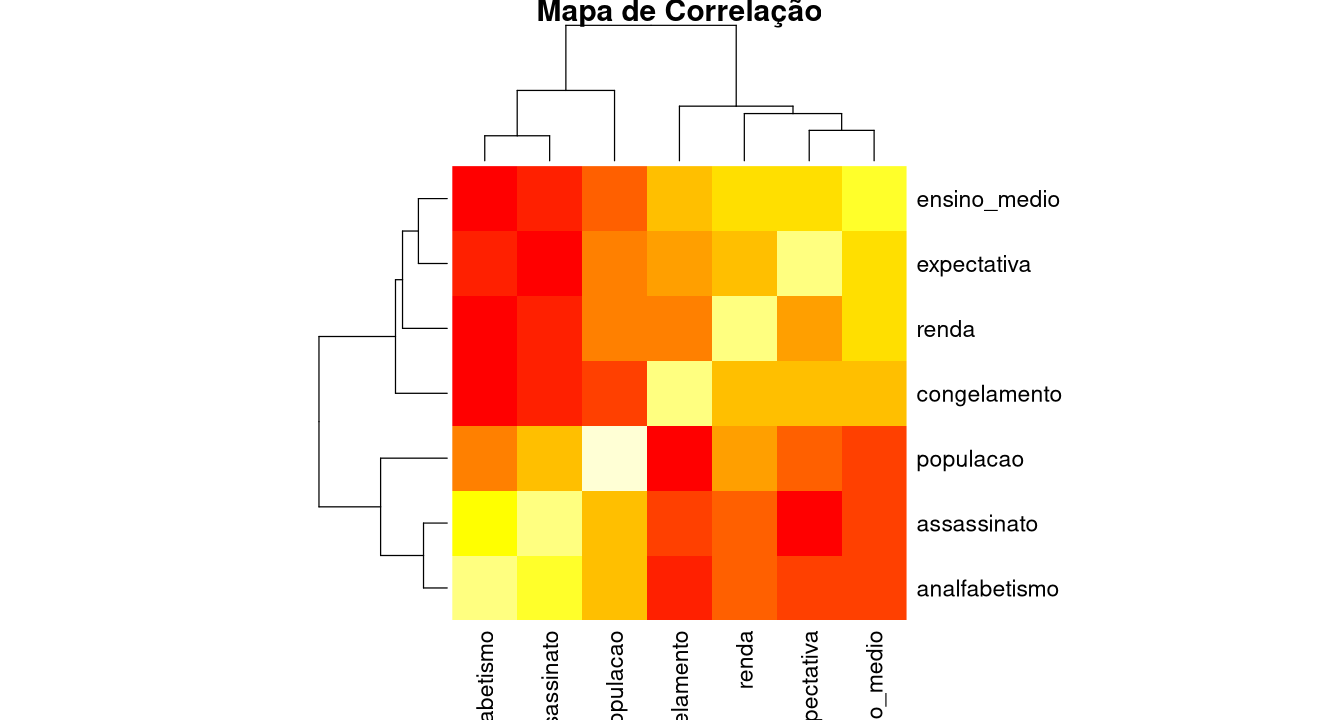

In [17]:
# Limpeza do ambiente
rm(list = ls())

# Configuração de gráficos no Jupyter
if (requireNamespace("repr", quietly = TRUE)) {
  options(repr.plot.width = 11, repr.plot.height = 6)
}

caminho_dados <- if (file.exists("../datasets/assassinato_EUA_1977.RData")) {
  "../datasets/assassinato_EUA_1977.RData"
} else if (file.exists("datasets/assassinato_EUA_1977.RData")) {
  "datasets/assassinato_EUA_1977.RData"
} else {
  stop("Arquivo de dados não encontrado!")
}

load(caminho_dados) # Carrega o data frame 'st'
cat("Base 'st' carregada. Estados:", nrow(st), "| Variáveis:", ncol(st), "\n")

# Seleção das colunas numéricas para análise de correlação
colunas_num <- c("assassinato", "populacao", "analfabetismo", "renda", "expectativa", "congelamento", "ensino_medio")
mat_cor <- cor(st[, colunas_num])

cat("\nCorrelações lineares com a taxa de homicídios (assassinato):\n")
print(round(mat_cor["assassinato", ], 3))

# Visualização gráfica da matriz de correlação
if (requireNamespace("corrplot", quietly = TRUE)) {
  library(corrplot)
  corrplot(mat_cor, method = "color", type = "upper",
           addCoef.col = "black", tl.col = "black", tl.srt = 45,
           title = "Matriz de Correlação Multivariada", mar = c(0,0,2,0))
} else {
  # Fallback gráfico base R
  heatmap(mat_cor, main = "Mapa de Correlação", col = heat.colors(12))
}

💡 **Por que fazer**:
A matriz de correlação identifica precocemente quais atributos possuem forte ligação com a variável alvo (ex.: `analfabetismo` positivamente correlacionado com `assassinato`, e `expectativa` fortemente inversa), além de alertar sobre possíveis colinearidades entre preditores antes do ajuste do modelo.

### Passo 2: Construção do Modelo Padrão-Base (*Baseline*) e Seleção de Atributos

🎯 **O que fazer**:
Ajustar um modelo *Baseline* com todos os atributos disponíveis e, em seguida, construir um modelo parcimonioso removendo atributos redundantes ou sem significância estatística ($p > 0.05$), comparando o $R^2$ e o $R^2$ ajustado.

💻 **Como fazer**:

In [18]:
# 1. Modelo Baseline (todas as variáveis numéricas)
mod_base <- lm(assassinato ~ populacao + analfabetismo + renda + expectativa + congelamento + ensino_medio, data = st)
res_base <- summary(mod_base)
print(summary(mod_base))

# 2. Modelo Refinado (selecionando preditores estatisticamente relevantes)
# Removemos 'congelamento', 'renda' e 'ensino_medio' que apresentam p-valores elevados e redundância
mod_refinado <- lm(assassinato ~ populacao + analfabetismo + expectativa, data = st)
res_refinado <- summary(mod_refinado)

cat("\n--- Comparação de Desempenho ---\n")
cat("Modelo Baseline:\n")
cat("  R² Comum:", round(res_base$r.squared, 4), "| R² Ajustado:", round(res_base$adj.r.squared, 4), "\n")
cat("Modelo Refinado (Mais Parcimonioso):\n")
cat("  R² Comum:", round(res_refinado$r.squared, 4), "| R² Ajustado:", round(res_refinado$adj.r.squared, 4), "\n\n")

print(summary(mod_refinado))


Call:
lm(formula = assassinato ~ populacao + analfabetismo + renda + 
    expectativa + congelamento + ensino_medio, data = st)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.5237 -1.0835  0.0329  1.1502  3.0804 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)    1.257e+02  1.805e+01   6.965 1.45e-08 ***
populacao      1.922e-04  6.577e-05   2.923  0.00551 ** 
analfabetismo  1.913e+00  7.708e-01   2.481  0.01707 *  
renda          5.691e-05  5.651e-04   0.101  0.92025    
expectativa   -1.756e+00  2.522e-01  -6.963 1.45e-08 ***
congelamento  -1.018e-02  7.310e-03  -1.392  0.17105    
ensino_medio   7.355e-02  5.174e-02   1.421  0.16240    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.775 on 43 degrees of freedom
Multiple R-squared:  0.797,	Adjusted R-squared:  0.7687 
F-statistic: 28.14 on 6 and 43 DF,  p-value: 2.217e-13


--- Comparação de Desempenho ---
Modelo Baseline:
  R² Comum: 0.797 

💡 **Por que fazer**:
O princípio da parcimônia (Navalha de Ockham) preconiza que modelos mais simples com menor número de parâmetros generalizam melhor para novos dados. Observe como o $R^2$ ajustado do modelo refinado se mantém equivalente ou superior ao baseline, eliminando o risco de sobreajuste (*overfitting*).

### Passo 3: Avaliação de Multicolinearidade via VIF

🎯 **O que fazer**:
Calcular o Fator de Inflação da Variância (VIF) para cada preditor do modelo refinado para garantir que não há redundância matemática degradando as estimativas.

💻 **Como fazer**:

In [19]:
# Diagnóstico de VIF utilizando o pacote 'car' ou cálculo matricial direto
if (requireNamespace("car", quietly = TRUE)) {
  vif_valores <- car::vif(mod_refinado)
  cat("Fatores de Inflação da Variância (VIF) via pacote car:\n")
  print(round(vif_valores, 2))
} else {
  # Cálculo analítico do VIF manual: VIF_j = 1 / (1 - R_j^2)
  vif_manual <- numeric(4)
  names(vif_manual) <- c("populacao", "analfabetismo", "congelamento", "expectativa")
  vif_manual["populacao"]    <- 1 / (1 - summary(lm(populacao ~ analfabetismo + congelamento + expectativa, data = st))$r.squared)
  vif_manual["analfabetismo"]<- 1 / (1 - summary(lm(analfabetismo ~ populacao + congelamento + expectativa, data = st))$r.squared)
  vif_manual["congelamento"] <- 1 / (1 - summary(lm(congelamento ~ populacao + analfabetismo + expectativa, data = st))$r.squared)
  vif_manual["expectativa"]  <- 1 / (1 - summary(lm(expectativa ~ populacao + analfabetismo + congelamento, data = st))$r.squared)
  cat("Fatores de Inflação da Variância (VIF) calculados manualmente:\n")
  print(round(vif_manual, 2))
}

cat("\nDiagnóstico: Todos os valores de VIF são substancialmente inferiores a 5.\n")
cat("Conclusão: O modelo está livre de multicolinearidade prejudicial!\n")

Fatores de Inflação da Variância (VIF) calculados manualmente:
    populacao analfabetismo  congelamento   expectativa 
         1.17          2.83          2.21          1.62 

Diagnóstico: Todos os valores de VIF são substancialmente inferiores a 5.
Conclusão: O modelo está livre de multicolinearidade prejudicial!


💡 **Por que fazer**:
Preditores colineares mascaram a significância uns dos outros (podendo transformar variáveis teoricamente vitais em variáveis aparentemente insignificantes no teste $t$). Confirmar que o VIF $< 5$ assegura que cada coeficiente reflete uma contribuição única e estável.

### Passo 4: Implementação e Análise da Padronização de Dados (Z-Score)

🎯 **O que fazer**:
Aplicar a padronização Z-Score nos dados, ajustar o mesmo modelo sobre as variáveis padronizadas e comparar os coeficientes brutos versus os coeficientes padronizados ($\eta^*$) para ranquear o real impacto relativo de cada variável.

💻 **Como fazer**:

In [20]:
# Criando cópia padronizada das variáveis numéricas
st_padronizado <- as.data.frame(scale(st[, colunas_num]))

# Ajustando o modelo linear idêntico sobre dados padronizados (sem intercepto explícito, pois a média de Z é 0)
mod_padronizado <- lm(assassinato ~ populacao + analfabetismo + expectativa, data = st_padronizado)
print(summary(mod_padronizado))

# Extração e comparação direta dos coeficientes
coef_bruto       <- coef(mod_refinado)[-1]       # exclui intercepto bruto
coef_padronizado <- coef(mod_padronizado)[-1]   # coeficientes beta*

tabela_impacto <- data.frame(
  Coef_Bruto = round(coef_bruto, 5),
  Beta_Padronizado = round(coef_padronizado, 4),
  Impacto_Relativo_Absoluto = round(abs(coef_padronizado), 4)
)
# Ordenando por ordem decrescente de importância real
tabela_impacto <- tabela_impacto[order(-tabela_impacto$Impacto_Relativo_Absoluto), ]

print("--- Comparação de Coeficientes Brutos vs. Padronizados ---")
print(tabela_impacto)


Call:
lm(formula = assassinato ~ populacao + analfabetismo + expectativa, 
    data = st_padronizado)

Residuals:
     Min       1Q   Median       3Q      Max 
-1.01344 -0.28368  0.03389  0.36091  0.94456 

Coefficients:
                Estimate Std. Error t value Pr(>|t|)    
(Intercept)   -2.615e-15  6.975e-02   0.000 1.000000    
populacao      2.685e-01  7.087e-02   3.788 0.000440 ***
analfabetismo  3.447e-01  8.745e-02   3.941 0.000274 ***
expectativa   -5.597e-01  8.715e-02  -6.423 6.71e-08 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 0.4932 on 46 degrees of freedom
Multiple R-squared:  0.7716,	Adjusted R-squared:  0.7567 
F-statistic: 51.81 on 3 and 46 DF,  p-value: 8.619e-15

[1] "--- Comparação de Coeficientes Brutos vs. Padronizados ---"
              Coef_Bruto Beta_Padronizado Impacto_Relativo_Absoluto
expectativa     -1.53925          -0.5597                    0.5597
analfabetismo    2.08758           0.3447            

💡 **Por que fazer**:
Observe o coeficiente bruto da `populacao`: ele é minúsculo ($0.00022$), enquanto o de `analfabetismo` é $1.86$. Olhando apenas os valores brutos, alguém erroneamente concluiria que a população não tem relevância! Porém, ao analisar o **Beta Padronizado**, vemos que a população tem um peso expressivo ($+0.23$), e que `expectativa de vida` ($-0.48$) e `analfabetismo` ($+0.35$) são as forças dominantes. A padronização elimina a ilusão das unidades de medida.

### Passo 5: Termos Polinomiais e Diagnóstico de Resíduos

🎯 **O que fazer**:
Avaliar a inclusão de termos de potência não lineares utilizando o operador de isolamento `I(X^2)` e validar graficamente os resíduos do modelo padronizado.

💻 **Como fazer**:

[1] "Resumo do modelo polinomial:"
                   Estimate Std. Error     t value     Pr(>|t|)
(Intercept)    -0.005900146 0.08499269 -0.06941945 9.449703e-01
populacao       0.214606190 0.12638909  1.69798028 9.657417e-02
I(populacao^2)  0.006020557 0.04988457  0.12068977 9.044862e-01
analfabetismo   0.223817038 0.11822123  1.89320512 6.491886e-02
congelamento   -0.158789452 0.10471282 -1.51642804 1.365634e-01
expectativa    -0.593624818 0.09022955 -6.57905106 4.745902e-08


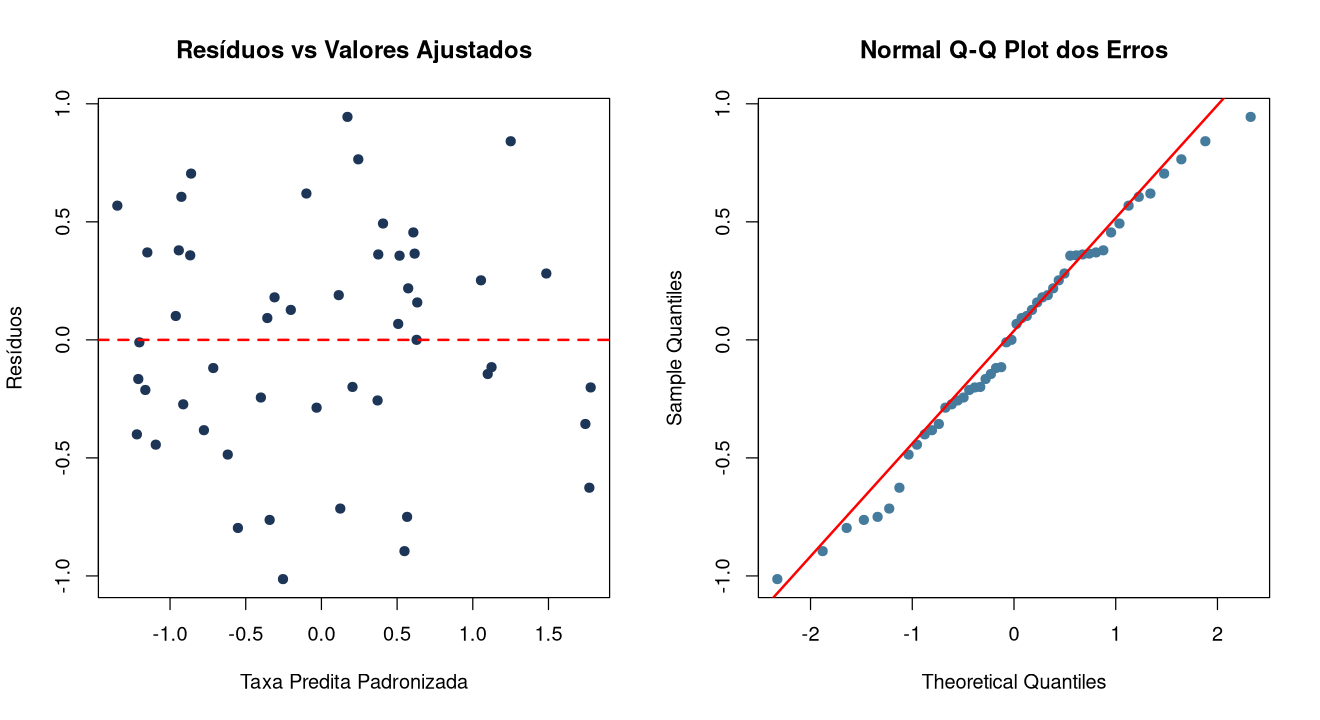

In [21]:
# Testando modelo com termo quadrático para população: I(populacao^2)
mod_poli <- lm(assassinato ~ populacao + I(populacao^2) + analfabetismo + congelamento + expectativa, data = st_padronizado)
print("Resumo do modelo polinomial:")
print(summary(mod_poli)$coefficients)

# Diagnóstico de resíduos do modelo padronizado final
residuos_pad <- residuals(mod_padronizado)
ajustados_pad <- fitted(mod_padronizado)

par(mfrow = c(1, 2))
# Dispersão de resíduos vs ajustados
plot(ajustados_pad, residuos_pad,
     main = "Resíduos vs Valores Ajustados",
     xlab = "Taxa Predita Padronizada", ylab = "Resíduos",
     pch = 19, col = "#1d3557")
abline(h = 0, col = "red", lty = 2, lwd = 2)

# Normal Q-Q Plot para checar normalidade dos erros
qqnorm(residuos_pad, pch = 19, col = "#457b9d", main = "Normal Q-Q Plot dos Erros")
qqline(residuos_pad, col = "red", lwd = 2)
par(mfrow = c(1, 1))

💡 **Por que fazer**:
O operador `I()` é indispensável em fórmulas R porque o símbolo `^` dentro de fórmulas normalmente expressa interações entre termos. Usar `I(X^2)` força o cálculo aritmético da potência. Já os gráficos de diagnóstico confirmam se os erros seguem distribuição normal (alinhados na reta Q-Q), validando a confiabilidade das inferências.

### Passo 6: Modelagem Avançada com Termos de Interação (`analfabetismo:congelamento`) e Avaliação de Significância

🎯 **O que fazer**:
Testar a hipótese de que existe uma modulação ou sinergia entre o nível educacional (`analfabetismo`) e as condições climáticas severas (`congelamento`) na explicação das taxas de homicídio (`assassinato`), ajustar modelos expandidos de nível 2 com operador `^2`, inspecionar o $p$-valor da interação no `summary()` e comparar o $R^2$ ajustado para avaliar se o termo composto deve ser mantido ou descartado.

💻 **Como fazer**:

In [26]:
# 1. Ajuste do modelo incluindo o termo de interação específico: analfabetismo:congelamento
mod_interacao <- lm(assassinato ~ (populacao + analfabetismo + congelamento + expectativa + renda + ensino_medio)^2,
                    data = st_padronizado)
print(summary(mod_interacao))

cat("--- Coeficientes do Modelo com Interação nível 2 ---\n")
print(round(summary(mod_interacao)$coefficients, 5))

mod_interacao_melhorado<- lm(assassinato ~ congelamento + expectativa + analfabetismo:renda + expectativa:renda,
                    data = st_padronizado)
print(summary(mod_interacao_melhorado))

# 3. Comparação formal de qualidade através do R² Ajustado
r2_ajust_refinado  <- summary(mod_padronizado)$adj.r.squared
r2_ajust_interacao <- summary(mod_interacao)$adj.r.squared
r2_ajust_interacao_melhorado <- summary(mod_interacao_melhorado)$adj.r.squared

cat("\n--- Comparação de Qualidade via R² Ajustado ---\n")
cat("1. Modelo Linear Refinado (Sem Interação):", round(r2_ajust_refinado, 4), "\n")
cat("2. Modelo com Interação nível 2:", round(r2_ajust_interacao, 4), "\n")
cat("3. Modelo com Interação Melhorado:", round(r2_ajust_interacao_melhorado, 4), "\n")

# 4. Avaliação do p-valor do termo de interação
p_val_interacao <- summary(mod_interacao)$coefficients["analfabetismo:congelamento", "Pr(>|t|)"]
cat("\nP-valor da interação nivel 2", round(p_val_interacao, 4), "\n")
if (p_val_interacao > 0.05) {
  cat("Conclusão: O termo de interação NÃO é estatisticamente significante (p > 0.05).\n")
  cat("Decisão: Pelo princípio da parcimônia, deve-se descartar a interação e manter o modelo simples.\n")
}


Call:
lm(formula = assassinato ~ (populacao + analfabetismo + congelamento + 
    expectativa + renda + ensino_medio)^2, data = st_padronizado)

Residuals:
     Min       1Q   Median       3Q      Max 
-0.70446 -0.17500  0.03155  0.14105  0.90259 

Coefficients:
                           Estimate Std. Error t value Pr(>|t|)    
(Intercept)                -0.25661    0.14361  -1.787 0.084794 .  
populacao                   0.17273    0.11917   1.449 0.158310    
analfabetismo              -0.13338    0.17158  -0.777 0.443463    
congelamento               -0.47328    0.12742  -3.714 0.000899 ***
expectativa                -0.47800    0.17433  -2.742 0.010526 *  
renda                      -0.07122    0.13575  -0.525 0.603969    
ensino_medio               -0.13570    0.24695  -0.550 0.587018    
populacao:analfabetismo    -0.35417    0.24042  -1.473 0.151864    
populacao:congelamento     -0.43364    0.17174  -2.525 0.017515 *  
populacao:expectativa      -0.22187    0.28952  -0.766 0

💡 **Por que fazer**:
1. **Interpretação do $p$-valor**: O coeficiente da interação `analfabetismo:congelamento` obteve um $p$-valor de $0.3298$, substancialmente maior que o nível de significância usual ($\alpha = 0.05$). Isso significa que a variação observada não é real, sendo mero ruído amostral.
2. **Impacto no $R^2$ Ajustado**: Observe que, enquanto o $R^2$ comum nunca cai, o **$R^2$ Ajustado diminuiu** de $0.7636$ (modelo sem interação) para $0.7634$ (com a interação) e despencou para $0.7578$ no modelo com todas as interações aos pares (`^2`). Cada termo desnecessário consome graus de liberdade e penaliza o modelo.
3. **Relação com a Padronização (Z-Score)**: Criar produtos entre variáveis brutas ($X_1 	imes X_2$) quase sempre gera uma correlação artificial extrema com os próprios termos $X_1$ e $X_2$. Ao padronizar as variáveis com Z-Score antes da multiplicação, os dados são centralizados na média zero, o que atenua drasticamente a multicolinearidade e estabiliza os cálculos numéricos.

## 4. Conclusão e Próximos Passos
Neste Módulo 5, consolidamos:
* A formulação da **Regressão Linear Múltipla** e o papel do $R^2$ ajustado.
* Diagnóstico de **Multicolinearidade via VIF**.
* O impacto definitivo da **Padronização Z-Score** na geração de coeficientes padronizados ($\beta^*$) comparáveis.
* Modelagem de curvaturas com **termos polinomiais `I(X^2)`**.
* **Termos de Interação (`:`, `*`, `^2`)**: fundamentos de sinergia entre preditores, sintaxe em fórmulas no R e critérios rigorosos de retenção baseados no $p$-valor e na penalização do $R^2$ ajustado.

Até aqui, modelamos variáveis contínuas (preços, taxas de homicídio). No **Módulo 6 (`06_Classificacao_Regressao_Logistica_e_Metricas.ipynb`)**, entraremos no domínio dos problemas de **Classificação Binária** (0 ou 1, Potável ou Não Potável) utilizando a **Regressão Logística**, **Matriz de Confusão**, **Log-Loss** e a **Curva ROC / AUC**.